# Insurance customers: similar clients, benefit prediction and data masking

**Ahmad Hassan** | AI Engineer

An insurer wants to know what machine learning can do with four facts about a customer (gender, age, income, number
of family members) and the number of insurance benefits they received in the last five years:

1. find customers similar to a given one (for marketing);
2. predict whether a new customer will receive any benefit, and whether that beats a dummy model;
3. predict the number of benefits with linear regression;
4. mask the personal data so it is hard to read, without breaking that regression.

**Result.** After removing 153 duplicate customers: scaled kNN (k=5, chosen by cross-validation) predicts whether a customer receives any benefit with a test F1 of **0.91**, against at most 0.21 for a random model. Linear regression explains only 43% of the variance in the number of benefits, because benefits rise in steps with age: a shallow decision tree explains 99.5%. Masking the features with a secret invertible matrix leaves the regression's predictions unchanged (to 10⁻¹²).

## What changed from the first version

- **153 duplicate customers were kept** (3% of rows), so some customers sat in both training and test sets; they are
  removed here, and the number of neighbours for kNN is chosen by cross-validation instead of by test scores.
- **R² was misreported.** The evaluation printed the *square root* of R², so the "R² 0.66" in the conclusion was
  really 0.43.
- **The algebra had errors.** The proof used "PᵀP = I", which is false for a random matrix; its last sentence said
  masking "does not affect the linear regression weights", but the weights do change (w_P = P⁻¹w) and only the
  predictions stay the same. Two answers said the data could not be recovered even when P is known, contradicting
  the code that recovered it.
- **"Manhattan distance is less sensitive to scale" was wrong**: on unscaled data, income dominates both distances.
- **The structure of the data was missed.** The number of benefits is a step function of age; a shallow decision tree
  explains almost all of it, which is why linear regression fits poorly. This is shown in Task 3.
- Course instructions, the reviewer's notes, the checklist and the appendices were removed, with the Colab path.

## The data

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import f1_score, mean_squared_error, r2_score
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MaxAbsScaler
from sklearn.tree import DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
raw = pd.read_csv("insurance_us.csv").rename(columns={"Gender": "gender", "Age": "age", "Salary": "income",
                                                      "Family members": "family_members", "Insurance benefits": "benefits"})
print(raw.shape, "| missing:", raw.isna().sum().sum(), "| duplicate rows:", raw.duplicated().sum())
df = raw.drop_duplicates().reset_index(drop=True)
FEATURES = ["gender", "age", "income", "family_members"]
print(df.describe().round(1))
print(df.benefits.value_counts().sort_index().to_dict())

(5000, 5) | missing: 0 | duplicate rows: 153
       gender     age   income  family_members  benefits
count  4847.0  4847.0   4847.0          4847.0    4847.0
mean      0.5    31.0  39895.8             1.2       0.2
std       0.5     8.5   9973.0             1.1       0.5
min       0.0    18.0   5300.0             0.0       0.0
25%       0.0    24.0  33200.0             0.0       0.0
50%       0.0    30.0  40200.0             1.0       0.0
75%       1.0    37.0  46600.0             2.0       0.0
max       1.0    65.0  79000.0             6.0       5.0
{0: 4284, 1: 423, 2: 114, 3: 18, 4: 7, 5: 1}


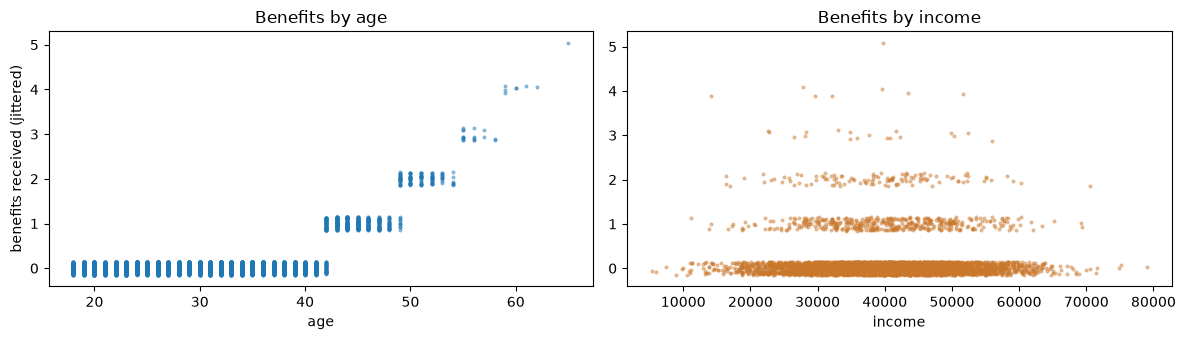

           min   max  size
benefits                  
0         18.0  42.0  4284
1         42.0  49.0   423
2         49.0  54.0   114
3         55.0  58.0    18
4         59.0  62.0     7
5         65.0  65.0     1


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].scatter(df.age, df.benefits + np.random.default_rng(SEED).uniform(-.15, .15, len(df)), s=4, alpha=.4)
ax[0].set_xlabel("age"); ax[0].set_ylabel("benefits received (jittered)"); ax[0].set_title("Benefits by age")
ax[1].scatter(df.income, df.benefits + np.random.default_rng(SEED + 1).uniform(-.15, .15, len(df)), s=4, alpha=.4, color="#c9772b")
ax[1].set_xlabel("income"); ax[1].set_title("Benefits by income")
plt.tight_layout(); plt.show()
steps = df.groupby("benefits").age.agg(["min", "max", "size"])
print(steps)

The number of benefits climbs in steps with age: nobody under 42 received one, ages 42 to 49 received one, and so on;
only the ages on a boundary (42, 49) appear in two groups. Income, gender and family size show no clear pattern.
The data behaves as if generated by a rule, so the models below should be judged with that in mind.

## Task 1. Similar customers

The k nearest customers to a given one, with the benefits column left out, for two distance metrics, on raw and on
scaled features (MaxAbsScaler divides each column by its largest absolute value).

In [3]:
def nearest(data, n, k, metric):
    nn = NearestNeighbors(n_neighbors=k, metric=metric).fit(data[FEATURES])
    dist, idx = nn.kneighbors(data.loc[[n], FEATURES], k)
    return df.loc[idx[0], FEATURES + ["benefits"]].assign(distance=dist[0].round(3))

scaled = df.copy()
scaled[FEATURES] = MaxAbsScaler().fit_transform(df[FEATURES])
n, k = 10, 5
for data, label in ((df, "raw"), (scaled, "scaled")):
    for metric in ("euclidean", "manhattan"):
        print(f"{label}, {metric}"); display(nearest(data, n, k, metric))

raw, euclidean


,gender,age,income,family_members,benefits,distance
10,1,25.0,36600.0,1,0,0.000
3924,1,25.0,36600.0,2,0,1.000
2007,1,26.0,36600.0,0,0,1.414
3169,1,26.0,36600.0,2,0,1.414
1492,0,26.0,36600.0,0,0,1.732


raw, manhattan


,gender,age,income,family_members,benefits,distance
10,1,25.0,36600.0,1,0,0.0
3924,1,25.0,36600.0,2,0,1.0
2007,1,26.0,36600.0,0,0,2.0
3169,1,26.0,36600.0,2,0,2.0
1492,0,26.0,36600.0,0,0,3.0


scaled, euclidean


,gender,age,income,family_members,benefits,distance
10,1,25.0,36600.0,1,0,0.000
4243,1,25.0,37400.0,1,0,0.010
1374,1,24.0,36700.0,1,0,0.015
756,1,24.0,36500.0,1,0,0.015
2219,1,26.0,36000.0,1,0,0.017


scaled, manhattan


,gender,age,income,family_members,benefits,distance
10,1,25.0,36600.0,1,0,0.000
4243,1,25.0,37400.0,1,0,0.010
1374,1,24.0,36700.0,1,0,0.017
756,1,24.0,36500.0,1,0,0.017
2219,1,26.0,36000.0,1,0,0.023


- **Raw features:** income is in tens of thousands while the other columns are below 70, so any difference in
  income outweighs every other column. All five raw neighbours have exactly this customer's income (36,600); only
  then do age, gender and family size count, and family size and gender vary among them. This is the same for both
  metrics: Manhattan distance is just as dominated by income as Euclidean.
- **Scaled features:** all four columns count; the neighbours match on gender and family size as well, with incomes
  close to but not equal to 36,600.
- Euclidean and Manhattan return the same neighbours here, in the same order; the choice of scaling matters far more
  than the choice of metric.

## Task 2. Will a customer receive any benefit?

In [4]:
y_any = (df.benefits > 0).astype(int)
X_train, X_test, y_train, y_test = train_test_split(df[FEATURES], y_any, test_size=0.3, stratify=y_any, random_state=SEED)
print(f"Customers with any benefit: {y_any.mean():.1%}")

rng = np.random.default_rng(SEED)
dummy = {f"random, P = {p:.2f}": f1_score(y_test, rng.binomial(1, p, len(y_test)))
         for p in (0.0, y_train.mean(), 0.5, 1.0)}
print(pd.Series(dummy, name="test F1").round(3))

Customers with any benefit: 11.6%
random, P = 0.00    0.000
random, P = 0.12    0.128
random, P = 0.50    0.180
random, P = 1.00    0.208
Name: test F1, dtype: float64


In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
knn_cv = pd.DataFrame({
    "raw": [cross_val_score(KNeighborsClassifier(k), X_train, y_train, cv=cv, scoring="f1").mean() for k in range(1, 11)],
    "scaled": [cross_val_score(make_pipeline(MaxAbsScaler(), KNeighborsClassifier(k)), X_train, y_train, cv=cv,
                               scoring="f1").mean() for k in range(1, 11)]}, index=range(1, 11)).rename_axis("k")
print(knn_cv.round(3).T)
best_k = int(knn_cv["scaled"].idxmax())
knn = make_pipeline(MaxAbsScaler(), KNeighborsClassifier(best_k)).fit(X_train, y_train)
logit = make_pipeline(MaxAbsScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print(f"\nTest F1, scaled kNN (k={best_k}, chosen by CV): {f1_score(y_test, knn.predict(X_test)):.3f}")
print(f"Test F1, logistic regression (for reference): {f1_score(y_test, logit.predict(X_test)):.3f}")

k          1      2      3      4      5      6      7      8      9      10
raw     0.586  0.279  0.301  0.125  0.135  0.081  0.094  0.039  0.049  0.044
scaled  0.914  0.908  0.921  0.905  0.925  0.898  0.913  0.889  0.903  0.883

Test F1, scaled kNN (k=5, chosen by CV): 0.910
Test F1, logistic regression (for reference): 0.780


The best random model reaches an F1 of about 0.2 (always saying "yes"). Scaled kNN is far better, because neighbours
that match on age share the outcome; unscaled kNN is poor, because its neighbours are chosen by income. Logistic
regression does worse than kNN: a single linear boundary cannot reproduce the step pattern at the age boundaries.

## Task 3. How many benefits? Linear regression from the normal equation

Weights from w = (XᵀX)⁻¹Xᵀy, with a column of ones for the intercept, on a 70:30 split.

In [6]:
class NormalEquationRegression:
    def fit(self, X, y):
        X1 = np.column_stack([np.ones(len(X)), X])
        self.w = np.linalg.inv(X1.T @ X1) @ X1.T @ y
        return self

    def predict(self, X):
        return np.column_stack([np.ones(len(X)), X]) @ self.w

X, y = df[FEATURES].to_numpy(dtype=float), df.benefits.to_numpy()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=SEED)
sc = MaxAbsScaler().fit(Xtr)
rows = {}
for label, (a, b) in {"raw": (Xtr, Xte), "scaled": (sc.transform(Xtr), sc.transform(Xte))}.items():
    p = NormalEquationRegression().fit(a, ytr).predict(b)
    rows[label] = {"RMSE": mean_squared_error(yte, p) ** .5, "R²": r2_score(yte, p)}
pd.DataFrame(rows).T.round(3)

,RMSE,R²
raw,0.363,0.432
scaled,0.363,0.432


Scaling changes the weights but not the predictions, so RMSE and R² are identical: a linear model can absorb any
rescaling of its inputs. The fit itself is weak (R² about 0.4) because benefits rise in steps with age, not along a
line. A model that can make steps shows the difference:

In [7]:
kf = KFold(5, shuffle=True, random_state=SEED)
compare = {}
for name, model, cols in [("linear regression, all features", LinearRegression(), FEATURES),
                          ("decision tree, age only", DecisionTreeRegressor(max_depth=4, random_state=SEED), ["age"]),
                          ("decision tree, all features", DecisionTreeRegressor(max_depth=5, random_state=SEED), FEATURES)]:
    p = cross_val_predict(model, df[cols], df.benefits, cv=kf)
    compare[name] = {"CV RMSE": mean_squared_error(df.benefits, p) ** .5, "CV R²": r2_score(df.benefits, p)}
display(pd.DataFrame(compare).T.round(3))
print(export_text(DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(df[["age"]], df.benefits), feature_names=["age"]))

,CV RMSE,CV R²
"linear regression, all features",0.355,0.427
"decision tree, age only",0.080,0.971
"decision tree, all features",0.034,0.995


|--- age <= 42.50
|   |--- age <= 41.50
|   |   |--- value: [0.00]
|   |--- age >  41.50
|   |   |--- value: [0.60]
|--- age >  42.50
|   |--- age <= 48.50
|   |   |--- value: [1.00]
|   |--- age >  48.50
|   |   |--- age <= 54.50
|   |   |   |--- value: [1.92]
|   |   |--- age >  54.50
|   |   |   |--- value: [3.35]



A decision tree on age alone explains about 97% of the variance, and with all four features about 99.5%: the tree
recovers the age cut-offs that generated the data. Linear regression is kept for Task 4 because the masking method
there is a property of linear models.

## Task 4. Masking personal data without breaking linear regression

Multiply the feature matrix by a random invertible matrix P: X' = XP. The values no longer look like ages or incomes,
yet linear regression on X' makes the same predictions.

In [8]:
rng = np.random.default_rng(SEED)
P = rng.random((4, 4))
while abs(np.linalg.det(P)) < 1e-6:          # make sure P is invertible
    P = rng.random((4, 4))
print(f"det(P) = {np.linalg.det(P):.4f}")
X_masked = X @ P
X_back = X_masked @ np.linalg.inv(P)
sample = [0, 3, 7]
display(pd.DataFrame(X[sample], columns=FEATURES).assign(view="original"))
display(pd.DataFrame(X_masked[sample], columns=[f"col{i}" for i in range(4)]).round(1).assign(view="masked"))
display(pd.DataFrame(X_back[sample], columns=FEATURES).round(6).assign(view="recovered with P⁻¹"))
print("Largest recovery error:", np.abs(X - X_back).max())

det(P) = 0.2434


,gender,age,income,family_members,view
0,1.0,41.0,49600.0,1.0,original
1,0.0,21.0,41700.0,2.0,original
2,1.0,25.0,38600.0,4.0,original


,col0,col1,col2,col3,view
0,6359.7,22380.4,18424.1,46000.7,masked
1,5345.6,18803.2,15479.1,38663.1,masked
2,4950.9,17413.0,14334.5,35794.4,masked


,gender,age,income,family_members,view
0,1.0,41.0,49600.0,1.0,recovered with P⁻¹
1,-0.0,21.0,41700.0,2.0,recovered with P⁻¹
2,1.0,25.0,38600.0,4.0,recovered with P⁻¹


Largest recovery error: 2.1827872842550278e-11


Someone who sees only X' cannot read ages or incomes from it, but anyone who also has P recovers X exactly (up to
rounding errors of about 10⁻¹¹, from floating-point arithmetic). So this is masking, not encryption: P must be
kept secret.

**Why predictions do not change.** With X' = XP and P invertible:

$$w_P = \big((XP)^T XP\big)^{-1}(XP)^T y = (P^T X^T X P)^{-1} P^T X^T y = P^{-1}(X^T X)^{-1}(P^T)^{-1} P^T X^T y
= P^{-1}(X^T X)^{-1}X^T y = P^{-1} w$$

using $(AB)^T = B^T A^T$, $(ABC)^{-1} = C^{-1}B^{-1}A^{-1}$ and $(P^T)^{-1}P^T = I$. The weights change, but the
predictions do not:

$$\hat y_P = X' w_P = X P P^{-1} w = X w = \hat y$$

so RMSE and R² are unchanged. (The intercept column is added after masking, so it is unaffected.)

In [9]:
p_plain = LinearRegression().fit(Xtr, ytr).predict(Xte)
p_masked = LinearRegression().fit(Xtr @ P, ytr).predict(Xte @ P)
print(f"plain:  RMSE {mean_squared_error(yte, p_plain) ** .5:.4f}  R² {r2_score(yte, p_plain):.4f}")
print(f"masked: RMSE {mean_squared_error(yte, p_masked) ** .5:.4f}  R² {r2_score(yte, p_masked):.4f}")
print("Largest difference between the two sets of predictions:", np.abs(p_plain - p_masked).max())

plain:  RMSE 0.3635  R² 0.4324
masked: RMSE 0.3635  R² 0.4324
Largest difference between the two sets of predictions: 1.0653700144303002e-12


## Conclusions

- **Similar customers:** scale the features first; without scaling, income alone decides who is similar, whichever
  distance is used.
- **Any benefit:** scaled kNN (k=5, chosen by cross-validation) reaches a test F1 of 0.91, against at most 0.21 for a random model and 0.78 for logistic regression; unscaled kNN stays below 0.6 even at its best k.
- **Number of benefits:** linear regression explains only about 43% of the variance; the data follows age
  cut-offs, which a decision tree captures almost exactly (R² 0.995 in cross-validation).
- **Masking:** multiplying by a secret invertible matrix hides the raw values and leaves linear-regression
  predictions unchanged, as the algebra and the test predictions show. It protects the data only as long as P stays
  secret.